# Optional compression of the joint shear vector

The joint measurement has 400 two-point entries, the shear-correlation block
$d_2=\xi_\pm$, and 80 three-point entries, the aperture-skewness block
$d_3=\langle M_\mathrm{ap}^3\rangle$. A likelihood can keep all 480 entries.
Compression replaces them by fixed linear combinations, which helps when
matching a published compressed analysis or when testing covariance
requirements.

The training calculation follows the numbered TATT Cobaya example directly.
It computes derivative arrays with the shared CosmoLike Fisher functions;
CAMB and the bispectrum model are supplied by that YAML. This first section
can be expensive. The subsequent compression cells use only those arrays.
A Fisher identity can close even for inaccurate derivatives, so train on
settings checked separately with the accuracy notebook. The cells have not
been physically rerun during this refactor.

The comparison covers ordinary xi-only MOPED and a xi-only compression that
keeps the joint local Gaussian Fisher matrix, followed by the separate
finite-simulation likelihood. Neither a local Fisher identity nor that
likelihood comparison reproduces the posterior analysis of Gomes et al.
(arXiv:2503.03964). [The statistical guide](README.md#compression) states the
assumptions and credits.

The training arrays and compression matrices are generated results under
`chains/`. There is no separate Fisher command or preparation workflow.
Run the numbered-model cells below when ready to generate the training
responses, then use the array-only compression comparison.


**Model and data.** The training inputs are explicit in the model and derivative cells:

| Choice | Value |
| --- | --- |
| Model | `EXAMPLE_EVALUATE4.yaml`, with dark energy opened explicitly |
| Derivatives | five-point derivatives at half the displayed absolute steps |
| Training metric | the numbered example’s fixed simulation covariance; a diagonal pilot for the independent basis |
| Parameters | 20: $\Omega_m$, $10^9A_\mathrm{s}$ (sampled; $\sigma_8$ is derived), $\Omega_b$, $H_0$, $n_s$, the TATT set $A_1$, $\eta_1$, $A_2$, $\eta_2$, $b_\mathrm{TA}$, the shear calibrations $m_{1\ldots4}$, the photo-z shifts $\Delta z_{1\ldots4}$, $w$, $w_a$ |
| Pilot noise | $10^{-4}$ per $\xi_\pm$ row, $10^{-8}$ per $M_\mathrm{ap}^3$ row |
| Mock count | $N_s=796$ for the finite-simulation demonstration |
| Saved bases | `chains/conditional_xi_compression.npz`, `chains/independent_pilot_compression.npz` |
| Threads | four OpenMP workers and one BLAS worker |

Words used throughout:

- **MOPED** (Massively Optimized Parameter Estimation and Data compression,
  [Heavens, Jimenez and Lahav, arXiv:astro-ph/9911102](https://arxiv.org/abs/astro-ph/9911102))
  compresses a data vector to one linear combination per parameter, chosen so
  the compressed vector keeps the Fisher information of the original under the
  training covariance.
- A **derivative column** is the change of the mean prediction per unit change
  of one parameter; the **Fisher matrix** $F=D^\mathsf{T}C^{-1}D$ measures the
  local Gaussian information of derivatives $D$ under covariance $C$.
- **Whitening** multiplies a vector by $L^{-1}$, where $C=LL^\mathsf{T}$ is the
  Cholesky factorization, so its entries lose their units and correlations.
- The **Hartlap factor**
  ([Hartlap, Simon and Schneider, arXiv:astro-ph/0608064](https://arxiv.org/abs/astro-ph/0608064))
  rescales an inverted sample covariance by $(N_s-N_d-2)/(N_s-1)$ to undo the
  inversion bias; the finite-simulation density below replaces that rescaling
  and must not be combined with it.
- The **Percival prescription** ([Percival, Friedrich, Sellentin and Heavens,
  arXiv:2108.10402](https://arxiv.org/abs/2108.10402)) is the posterior density
  for a sample covariance from $N_s$ independent Gaussian mocks, with an
  exponent that depends on the kept data entries and fitted parameters.

In [1]:
%matplotlib inline
%config InlineBackend.figure_format = 'retina'
import os
# BLAS must not start another worker team inside the native OpenMP calculation.
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["VECLIB_MAXIMUM_THREADS"] = "1"
os.environ["OMP_NUM_THREADS"] = "4"

from copy import deepcopy
from pathlib import Path
import hashlib
import sys
import numpy as np
import matplotlib
from matplotlib import pyplot as plt
from scipy.linalg import solve_triangular
from cobaya.model import get_model
from cobaya.yaml import yaml_load_file, yaml_dump_file

project = Path.cwd().resolve()
while not (project / "EXAMPLE_EVALUATE3.yaml").exists():
    if project == project.parent:
        raise FileNotFoundError("Open this notebook from the DES project directory.")
    project = project.parent
cocoa = project.parents[1]
sys.path.insert(0, str(project / "interface"))
sys.path.insert(0, str(cocoa / "external_modules/code/cosmolike_core"))
import cosmolike_des_3pcf_interface as ci
import cosmolike_notebook_utils.fisher as cnu

# Numbered Cocoa YAMLs resolve package and dataset paths from the Cocoa directory.
os.chdir(cocoa)
from cobaya.likelihoods.des_3pcf.compression import fit_compression, load_compression

# Figure style of the whole notebook: the shared plotting functions never change
# rcParams, so these lines set every font, tick and grid default.
matplotlib.rcParams['mathtext.fontset'] = 'stix'
matplotlib.rcParams['font.family'] = 'STIXGeneral'
matplotlib.rcParams['mathtext.rm'] = 'Bitstream Vera Sans'
matplotlib.rcParams['mathtext.it'] = 'Bitstream Vera Sans:italic'
matplotlib.rcParams['mathtext.bf'] = 'Bitstream Vera Sans:bold'
matplotlib.rcParams['xtick.bottom'] = True
matplotlib.rcParams['xtick.top'] = False
matplotlib.rcParams['ytick.right'] = False
matplotlib.rcParams['axes.edgecolor'] = 'black'
matplotlib.rcParams['axes.linewidth'] = '1.0'
matplotlib.rcParams['axes.labelsize'] = 'medium'
matplotlib.rcParams['axes.grid'] = True
matplotlib.rcParams['grid.linewidth'] = '0.0'
matplotlib.rcParams['grid.alpha'] = '0.18'
matplotlib.rcParams['grid.color'] = 'lightgray'
matplotlib.rcParams['legend.labelspacing'] = 0.77
matplotlib.rcParams['savefig.bbox'] = 'tight'
matplotlib.rcParams['savefig.format'] = 'pdf'


## The cross-covariance changes which xi combinations matter

Write the fixed covariance in blocks $C_{22},C_{23},C_{33}$ and the derivative
matrix as $D_2,D_3$, with 2 marking the two-point block and 3 the three-point
block. A derivative column is the change of the mean per unit parameter. A row
with zero mean response can still improve a joint constraint, because it can
trace a noise fluctuation that it shares with another observable.

For example, let $D_2=(1,0)^\mathsf{T}$, $D_3=1$, $C_{22}=I$,
$C_{23}=(0,r)^\mathsf{T}$ and $C_{33}=1$. Ordinary xi-only MOPED keeps only the
first xi row and discards the second row, the one that traces the three-point
noise. The full amplitude information is $2+r^2/(1-r^2)$; the compressed vector
keeps only 2.

To keep the joint information, first form the conditional covariance and
derivative,

$$
S=C_{22}-C_{23}C_{33}^{-1}C_{32},\qquad
J=D_2-C_{23}C_{33}^{-1}D_3.
$$

With $S=LL^\mathsf{T}$, choose orthonormal columns $Q$ spanning $L^{-1}J$. The
xi weights are $W=Q^\mathsf{T}L^{-1}$. Apply $T=\operatorname{diag}(W,I)$ to the
data and to every prediction, and use $TCT^\mathsf{T}$ including its cross
block. The number of kept xi combinations is the numerical rank of the trained
responses, and every varied nuisance parameter must enter the training.

In [2]:
toy_covariance = np.array([[1., 0., 0.], [0., 1., .6], [0., .6, 1.]])
toy_derivatives = np.array([[1.], [0.], [1.]])
for mode in ("xi_moped", "conditional_xi", "joint"):
    basis = fit_compression(
        covariance=toy_covariance, derivatives=toy_derivatives,
        labels=["xi1", "xi2", "map3"], kind=["xip", "xim", "map3"],
        mode=mode, metadata={"source": "explicit three-row example"},
    )
    response = basis.apply(values=toy_derivatives)
    reduced = basis.covariance(values=toy_covariance)
    information = float((response.T @ np.linalg.solve(reduced, response))[0, 0])
    print(mode, "retained rows:", basis.matrix.shape[0], "information:", information)


xi_moped retained rows: 2 information: 2.0
conditional_xi retained rows: 2 information: 2.5625
joint retained rows: 1 information: 2.5625


## Compute the training responses, then build the bases

The calculation below preserves the local information of the displayed model’s
derivative array. It cannot restore information absent from an inaccurate
derivative or from a parameter left out of the training: the fit happens once,
at the recorded fiducial, so a sampled feedback amplitude added later needs its
own derivative and a fresh basis.

The first three bases use the numbered example’s covariance as their training metric,
which suits the fixed-Gaussian algebra demonstration; the finite-simulation
prescription below gets its own basis instead. That pilot basis trains on a
fixed diagonal teaching covariance with noise scales $10^{-4}$ for xi and
$10^{-8}$ for the aperture rows, numbers chosen to expose the mixed units, not
to predict a survey covariance.
The next cells open dark energy explicitly, retain all the unmasked TATT
rows, and differentiate the numbered Cobaya likelihood. No parameter
conversion or independent matter calculation is hidden in a study driver.
The prediction function calls the same likelihood as the inference examples.


In [3]:
# Train this basis on the unmasked, uncompressed numbered TATT example.
example = "EXAMPLE_EVALUATE4.yaml"
info = yaml_load_file(str(project / example))
fiducial = dict(info["sampler"]["evaluate"]["override"])
info.pop("sampler")
info.pop("output", None)
info["likelihood"]["des_3pcf.joint_shear"]["omp_threads"] = 4

# Unlike the numbered inference example, this diagnostic varies dark energy.
# Removing the fixed values lets Cobaya pass the two stencil coordinates to CAMB.
info["params"]["w"] = {
    "prior": {"min": -2.0, "max": -0.3},
    "ref": -1.0,
}
info["params"]["wa"] = {
    "prior": {"min": -2.0, "max": 2.0},
    "ref": 0.0,
}
fiducial["w"] = -1.0
fiducial["wa"] = 0.0

# These are absolute physical displacements, not percentages of a fiducial.
# Small nuisance steps and larger dark-energy steps therefore have explicit units.
steps = {
    "omegam": 0.003,
    "As_1e9": 0.024,
    "omegab": 0.0005,
    "H0": 0.5,
    "ns": 0.005,
    "DES_A1_1": 0.01,
    "DES_A1_2": 0.03,
    "DES_A2_1": 0.02,
    "DES_A2_2": 0.03,
    "DES_BTA_1": 0.02,
    "DES_M1": 0.001,
    "DES_M2": 0.001,
    "DES_M3": 0.001,
    "DES_M4": 0.001,
    "DES_DZ_S1": 0.001,
    "DES_DZ_S2": 0.001,
    "DES_DZ_S3": 0.001,
    "DES_DZ_S4": 0.001,
    "w": 0.02,
    "wa": 0.04,
}
# Gaussian source-calibration widths enter once. Flat prior limits do not
# supply Gaussian information; their posterior truncation is absent here.
priors = {
    "DES_M1": 0.0091,
    "DES_M2": 0.0078,
    "DES_M3": 0.0076,
    "DES_M4": 0.0076,
    "DES_DZ_S1": 0.018,
    "DES_DZ_S2": 0.015,
    "DES_DZ_S3": 0.011,
    "DES_DZ_S4": 0.017,
}

In [4]:
def get_dv(parameters):
    """Evaluate the current numbered Cobaya model at a physical parameter point.

    Cobaya runs its declared theory blocks before the DES likelihood. The
    likelihood retains the full mean it evaluated; the native selector applies
    its data mask and compression. A Fisher displacement must reach that same
    prediction, not another CAMB or bispectrum preparation route.

    Arguments:
      parameters = dictionary of sampled physical parameters for the current model.
    Returns:
      Owned one-dimensional selected data vector, in the covariance's row order.
    Raises:
      RuntimeError if the likelihood evaluation is not finite.
    Side effects:
      Updates the current model and the process-global native cosmology.
    """
    value = model.loglike(
        params_values=parameters,
        return_derived=False,
        cached=False,
    )
    if not np.isfinite(value):
        raise RuntimeError("A Fisher point has nonfinite likelihood; inspect that point.")
    return np.array(
        object=ci.select_joint_data_vector(prediction=likelihood.last_datavector),
        dtype=np.float64,
        copy=True,
    )

In [5]:
model = get_model(info_or_yaml_or_file=info)
likelihood = model.likelihood["des_3pcf.joint_shear"]
try:
    # Example 2 has no input mask or compression. Its physical labels therefore
    # identify each selected derivative row; do not borrow them for another mask.
    covariance = np.array(object=ci.get_joint_covariance(), copy=True)
    labels = likelihood.rows.labels.copy()
    kinds = likelihood.rows.kind.copy()
    row_bins = likelihood.rows.bins.copy()
    row_angles = likelihood.rows.angles.copy()
    predict = cnu.ExactMeanCache(predict=get_dv)
    names, mean, derivatives_h, derivatives = cnu.differentiate(
        predict=predict,
        parameters=fiducial,
        steps=steps,
    )
    if len(labels) != mean.size:
        raise ValueError("Compression training needs labels matched to the selected rows.")
finally:
    model.close()

# Compression trains on likelihood derivatives alone. The source-calibration
# priors enter once when comparing marginal errors, after forming information.
prior_fisher = np.zeros((len(names), len(names)))
for name, sigma in priors.items():
    prior_fisher[names.index(name), names.index(name)] = 1.0 / sigma**2

# Retain ordinary numerical arrays and the exact numbered configuration so this
# potentially long derivative calculation can be inspected without rerunning it.
directory = project / "chains" / "compression"
directory.mkdir(parents=True, exist_ok=True)
archive = directory / "training.npz"
np.savez(
    file=archive,
    fiducial_covariance=covariance,
    derivatives_h=derivatives_h,
    derivatives_h2=derivatives,
    row_labels=labels,
    row_kind=kinds,
    row_bins=row_bins,
    row_angles_radians=row_angles,
    parameter_names=np.asarray(names),
    absolute_steps=np.asarray([steps[name] for name in names]),
    mean=mean,
    fisher_prior=prior_fisher,
)
yaml_dump_file(
    file_name=str(directory / "training.yaml"),
    data=info,
    error_if_exists=False,
)
archive_hash = hashlib.sha256(archive.read_bytes()).hexdigest()
training = {
    "archive": str(archive.relative_to(project)),
    "archive_sha256": archive_hash,
    "parameter_names": names,
    "fiducial": fiducial,
    "derivative_field": "derivatives_h2",
    "covariance_field": "fiducial_covariance",
    "covariance_training_independent": False,
    "interpretation": "local Gaussian compression; derivative convergence checked separately",
}

[camb] `camb` module loaded successfully from /Users/vivianmiranda/data/COCOA/november2026/sbu_cosmolike/cocoa/Cocoa/external_modules/code/CAMB/camb


[des_3pcf.joint_shear] Average evaluation time for des_3pcf.joint_shear: 10.121 s  (120 evaluations)


[camb.transfers] Average evaluation time for camb.transfers: 0.504461 s  (120 evaluations)


[camb] Average evaluation time for camb: 0.253192 s  (120 evaluations)


[bihalofit] Average evaluation time for bihalofit: 5.26497 s  (120 evaluations)


In [6]:
bases = {}
for mode in ("xi_moped", "conditional_xi", "joint"):
    bases[mode] = fit_compression(
        covariance=covariance, derivatives=derivatives, labels=labels,
        kind=kinds, mode=mode, metadata=training,
    )
    print(mode, "output rows:", bases[mode].matrix.shape[0],
          "response rank:", bases[mode].metadata["rank"])
print("Input:", archive_hash, "parameters:", names)

xi_moped output rows: 100 response rank: 20
conditional_xi output rows: 100 response rank: 20
joint output rows: 20 response rank: 20
Input: fc1959ace70f82c4a73a0857d962a37a3a5c9bac3ca36ff5ef37f2c8cd2acef7 parameters: ['omegam', 'As_1e9', 'omegab', 'H0', 'ns', 'DES_A1_1', 'DES_A1_2', 'DES_A2_1', 'DES_A2_2', 'DES_BTA_1', 'DES_M1', 'DES_M2', 'DES_M3', 'DES_M4', 'DES_DZ_S1', 'DES_DZ_S2', 'DES_DZ_S3', 'DES_DZ_S4', 'w', 'wa']


In [7]:
full_information = cnu.fisher_matrix(
    covariance=covariance,
    derivatives=derivatives,
    names=names,
)
normalization = np.sqrt(np.diag(full_information))
information = {}
for mode, basis in bases.items():
    information[mode] = cnu.fisher_matrix(
        covariance=basis.covariance(values=covariance),
        derivatives=basis.apply(values=derivatives),
        names=names,
    )
    error = (information[mode] - full_information)
    error /= normalization[:, None] * normalization[None, :]
    print(mode, "maximum normalized Fisher difference:", np.max(np.abs(error)))
    if mode in ("joint", "conditional_xi"):
        assert np.max(np.abs(error)) < 1.e-8
full_variance = np.diag(cnu.parameter_covariance(
    fisher=full_information + prior_fisher,
    names=names,
))
error_ratios = {}
for mode, matrix in information.items():
    variance = np.diag(cnu.parameter_covariance(
        fisher=matrix + prior_fisher,
        names=names,
    ))
    error_ratios[mode] = np.sqrt(variance / full_variance)


xi_moped maximum normalized Fisher difference: 0.3747768600747355
conditional_xi maximum normalized Fisher difference: 1.4322158781474483e-15
joint maximum normalized Fisher difference: 1.513050249276709e-15


The plot compares marginal errors after applying the same calibration priors.
A ratio of one means the same local error as the full 480-row calculation, and
the conditional construction and the full joint compression overlap that value
to numerical precision. The check covers the kept derivative subspace only, not
the nonlinear posterior shape or the convergence of the physical prediction.

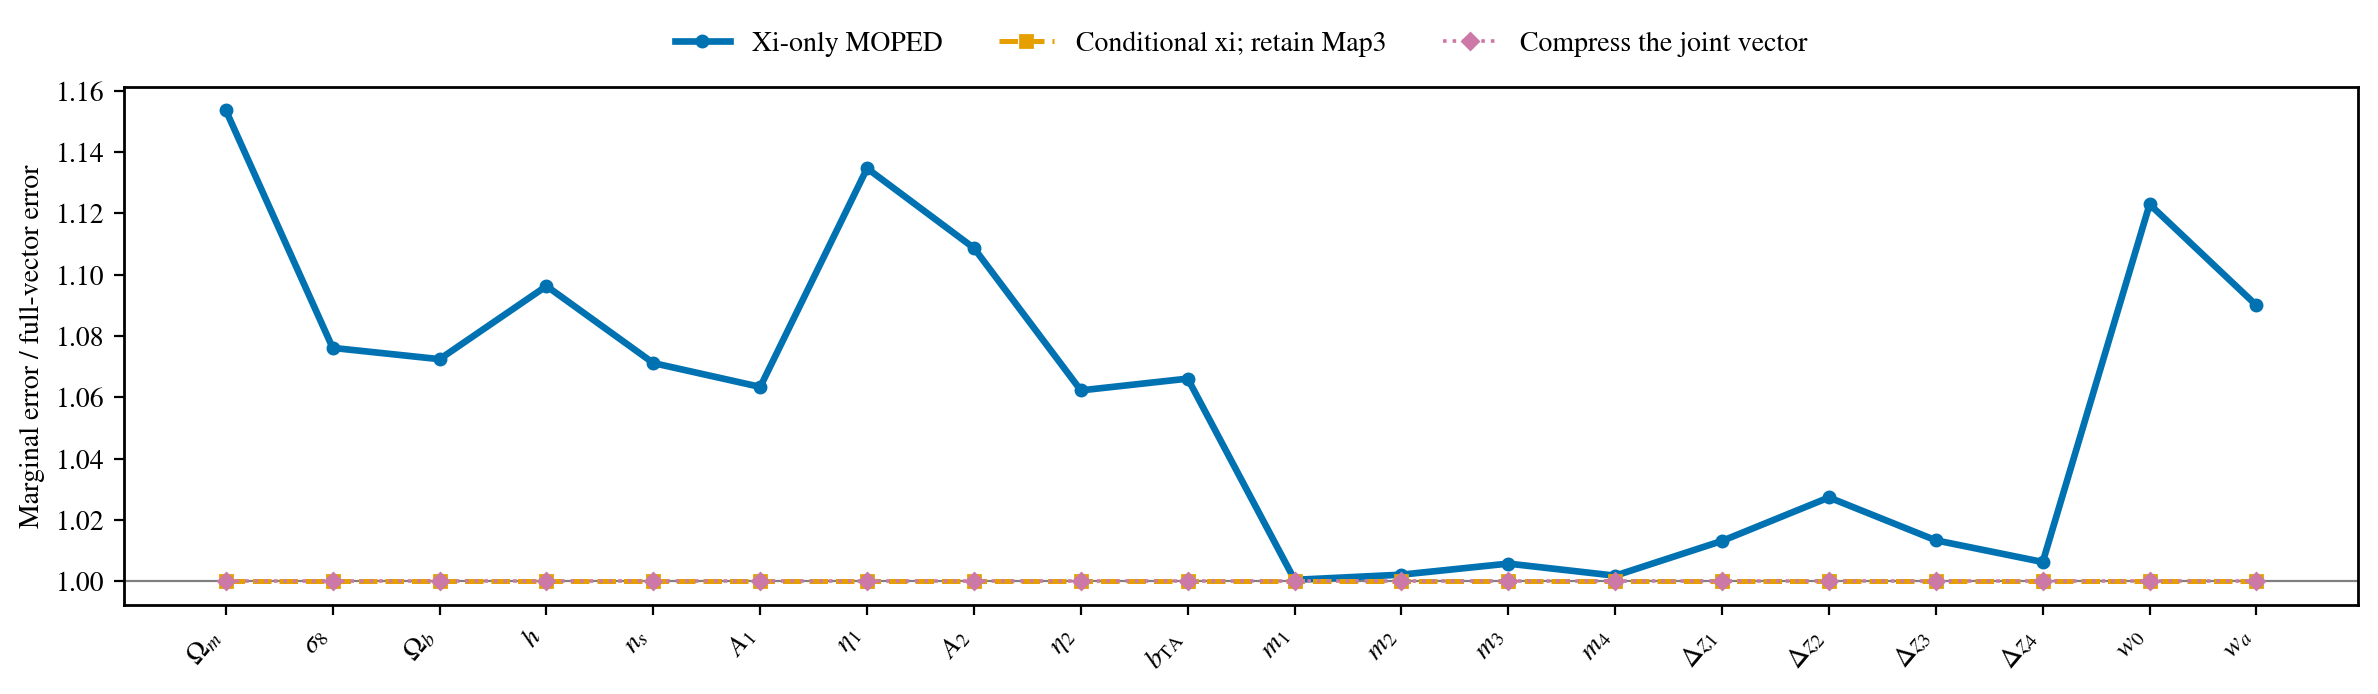

In [8]:
figure, axes = plt.subplots(figsize=(12, 3.6))
styles = {
    "xi_moped": ("Xi-only MOPED", "#0072B2", "o", 2.4, "-"),
    "conditional_xi": ("Conditional xi; retain Map3", "#E69F00", "s", 1.8, "--"),
    "joint": ("Compress the joint vector", "#CC79A7", "D", 1.3, ":"),
}
for mode, (label, color, marker, width, pattern) in styles.items():
    axes.plot(np.arange(len(names)), error_ratios[mode], label=label, color=color,
              marker=marker, markersize=4, linewidth=width, linestyle=pattern)
parameter_labels = [
    r"$\Omega_m$", r"$10^9A_\mathrm{s}$", r"$\Omega_b$", r"$H_0$", r"$n_s$",
    r"$A_1$", r"$\eta_1$", r"$A_2$", r"$\eta_2$", r"$b_{\rm TA}$",
    r"$m_1$", r"$m_2$", r"$m_3$", r"$m_4$",
    r"$\Delta z_1$", r"$\Delta z_2$", r"$\Delta z_3$", r"$\Delta z_4$",
    r"$w$", r"$w_a$",
]
axes.set_xticks(ticks=np.arange(len(names)), labels=parameter_labels, rotation=50,
               ha="right")
axes.set_ylabel(ylabel="Marginal error / full-vector error")
axes.axhline(y=1., color="gray", linewidth=.8, zorder=0)
legend = axes.legend(loc="lower center", bbox_to_anchor=(.5, 1.01),
                     ncol=3, frameon=False)
figure.tight_layout()
figure.canvas.draw()
# The external legend must stay above every drawn data point.
legend_box = legend.get_window_extent(figure.canvas.get_renderer())
for line in axes.lines:
    display_points = axes.transData.transform(line.get_xydata())
    assert np.max(display_points[:, 1]) < legend_box.y0
plot_directory = project / "chains" / "compression"
plot_directory.mkdir(parents=True, exist_ok=True)
figure.savefig(fname=plot_directory / "local_errors.png", dpi=160, pad_inches=.15)
figure.savefig(fname=plot_directory / "local_errors.pdf", pad_inches=.15)
plt.show()


## Save the experiment once, and use it consistently

The saved matrix carries the exact input labels. A likelihood picks its
physical rows first, then checks that those labels match the training order,
and then transforms the observed values, every theory vector and both
covariance axes. A compressed row has no single angular separation, so it
carries a mode label rather than an invented physical coordinate.

The first saved basis below is the conditional Gaussian demonstration; the
second trains on the independent diagonal pilot. Neither is the published
compression matrix of Gomes et al. (arXiv:2503.03964): an exact posterior
reproduction would import that matrix and its exact row order instead.

In [9]:
def save_or_verify(basis, destination):
    """Refuse to replace a saved experiment with different arrays or metadata."""
    if destination.exists():
        previous = load_compression(path=destination)
        np.testing.assert_array_equal(x=previous.matrix, y=basis.matrix)
        assert previous.metadata_json == basis.metadata_json
    else:
        basis.save(path=destination)

save_or_verify(basis=bases["conditional_xi"],
               destination=project / "chains" / "conditional_xi_compression.npz")
pilot_noise = np.full(labels.size, 1.e-4)
pilot_noise[kinds == "map3"] = 1.e-8
pilot_covariance = np.diag(pilot_noise**2)
pilot_training = dict(training)
pilot_training["covariance_field"] = "fixed_diagonal_teaching_pilot"
pilot_training["covariance_training_independent"] = True
pilot_training["pilot_noise"] = {"xi": 1.e-4, "map3": 1.e-8}
pilot_basis = fit_compression(
    covariance=pilot_covariance, derivatives=derivatives, labels=labels,
    kind=kinds, mode="conditional_xi", metadata=pilot_training,
)
save_or_verify(basis=pilot_basis,
               destination=project / "chains" / "independent_pilot_compression.npz")
print("Saved fixed matrices with labels, training point and input hash.")


Saved fixed matrices with labels, training point and input hash.


## Finite simulation uncertainty is a separate assumption

The Percival prescription uses the ordinary sample covariance from $N_s$
independent Gaussian mock vectors, and its posterior density carries an
exponent that depends on the number of kept data entries and fitted mean
parameters (Percival, Friedrich, Sellentin and Heavens, arXiv:2108.10402: the
finite-simulation posterior density and its exponent). It has no Hartlap
rescaling. The code counts rows after compression and requires a normalized
data density, so not every $N_s>N_d+4$ configuration passes.

The demonstration uses $N_s=796$ with the independent pilot basis, a local
linear mean, and the fiducial mean as its synthetic datum. The Gaussian-mock,
independence and fixed-covariance assumptions appear explicitly in the code
below. Four footprints cut from one full sky need not be independent, and this
example does not verify that assumption for the Y3 mocks.

Recomputing the Percival exponent after compression defines the compressed
statistical analysis; it is not the marginal of the full-vector t density, and
strong priors or nonlinear responses can change the frequentist coverage
argument. The
[Friedrich–Eifler precision-matrix expansion](https://arxiv.org/abs/1703.07786)
uses simulations differently, and this likelihood must not receive it as a raw
sample covariance.

In [10]:
baseline = {}
for name in names:
    baseline[name] = fiducial[name]

def local_mean(parameters):
    """Evaluate the trained first-order Taylor model, without physical claims."""
    displacement = np.array([parameters[name] - baseline[name] for name in names])
    return mean + derivatives @ displacement

# This example assumes independent Gaussian mocks and an independent pilot
# compression, as discussed above. Supply raw sample S, with no Hartlap factor.
ci.init_joint_data(
    data=mean,
    covariance=covariance,
    indices=np.arange(mean.size, dtype=np.int32),
    compression=pilot_basis.matrix,
    mock_count=796,
    parameter_count=len(names),
)
point = dict(baseline)
point["DES_A1_1"] += .1
print("Retained rows:", ci.get_joint_data().size, "Percival exponent:", ci.get_joint_exponent())
print("Local fiducial log density:", ci.compute_joint_loglike(prediction=local_mean(parameters=baseline)))
print("Local displaced log density:", ci.compute_joint_loglike(prediction=local_mean(parameters=point)))


Retained rows: 100 Percival exponent: 734.8263430637885
Local fiducial log density: 1810.8149119570257
Local displaced log density: 1810.5423693071737


The likelihood reads the fixed matrix named by `compression_file` in its
`.dataset`. [EXAMPLE_NAUTILUS5.yaml](EXAMPLE_NAUTILUS5.yaml) selects the
independent pilot and the finite-simulation prescription; its synthetic mean
uses the shared TATT prediction. After creating that pilot, run
`python projects/des_3pcf/EXAMPLE_NAUTILUS5.py --check` from activated
`Cocoa/` to evaluate one fiducial without sampling. The matching evaluate
and MCMC examples for case 4 use the same inputs. This notebook launches no sampler.

**Credits.** The compression comparison follows the MOPED construction of
[Heavens, Jimenez and Lahav](https://arxiv.org/abs/astro-ph/9911102), and the
finite-simulation model follows
[Percival, Friedrich, Sellentin and Heavens](https://arxiv.org/abs/2108.10402).
The reproduction targets are the
[methods paper](https://arxiv.org/abs/2503.03964) of Sugiyama and Gomes, the
[TATT paper](https://arxiv.org/abs/2601.09133) of Gomes et al.,
[fastnc](https://github.com/git-sunao/fastnc/tree/tatt), the
[Y3 integrator](https://github.com/rchgomes/3pcf_integrator) and the
[Y6 pipeline](https://github.com/rchgomes/desy6-3pcf); the
[project README](README.md#acknowledgements) carries the acknowledgements.